
# CIAuthE — Interpretable Modeling Support with XGBoost SHAP

Este notebook implementa a análise interpretável do **CIAuthE (Cloud Identity Authentication Events)** com XGBoost e SHAP.

O objetivo não é estabelecer *ground truth* de ataque. O modelo aprende a reproduzir o sinal operacional `provider_suspicious`, e o SHAP é utilizado para explicar quais atributos contribuem para essa saída.

A análise segue quatro blocos:

1. **Temporal holdout** para avaliação prospectiva;
2. **Global explanation of feature importance** no conjunto temporal de teste;
3. **Local explanations at event level** com seleção determinística de eventos;
4. **Rolling temporal validation** para avaliar estabilidade temporal das explicações.

`provider_suspicious` é exclusivamente a variável-alvo e nunca entra como preditor.



## 1. Dependências

```bash
pip install pandas numpy scipy scikit-learn xgboost shap matplotlib joblib
```


In [1]:

from pathlib import Path
import os
import json
import math
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import sparse
from scipy.stats import spearmanr

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

import joblib
import xgboost as xgb
from xgboost import XGBClassifier
import shap

warnings.filterwarnings("ignore", category=FutureWarning)

print("pandas:", pd.__version__)
print("xgboost:", xgb.__version__)
print("shap:", shap.__version__)


e:\Developer\suspiciouslogin\.env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


pandas: 3.0.6
xgboost: 3.4.1
shap: 0.54.1


## 2. Configuração

In [3]:

RANDOM_STATE = 42

# ------------------------------------------------------------
# Main temporal split
# ------------------------------------------------------------
TRAIN_FRACTION = 0.70
VALID_FRACTION = 0.15
TEST_FRACTION = 0.15

# ------------------------------------------------------------
# Main SHAP analysis
# ------------------------------------------------------------
# "test" = recommended for the article: explain held-out future events.
# "all"  = explain the whole release; includes in-sample observations.
SHAP_SCOPE = "test"

# None = explain every event in the selected scope.
# Use an integer (e.g. 2000) only for faster exploratory runs.
SHAP_MAX_ROWS = None

# Exact Tree SHAP is recommended for the article.
SHAP_APPROXIMATE = False

# ------------------------------------------------------------
# Rolling temporal validation
# ------------------------------------------------------------
# Observed months are ordered chronologically.
# The first 4 months form the initial expanding training window.
# With the current release, this makes April 2026 the first test month.
ROLLING_INITIAL_TRAIN_MONTHS = 4

# The final observed month (August 2026) is partial, so exclude it
# from the default rolling comparison.
ROLLING_EXCLUDE_PARTIAL_LAST_MONTH = True

# None = calculate exact XGBoost SHAP contributions for every event
# in each rolling test month.
ROLLING_SHAP_MAX_ROWS = None

# ------------------------------------------------------------
# Model / output
# ------------------------------------------------------------
USE_CLASS_WEIGHT = True
TOP_N = 15

def locate_public_csv():
    override = os.environ.get("SUSPICIOUSLOGIN_PUBLIC_CSV")
    if override:
        p = Path(override).expanduser()
        if not p.exists():
            raise FileNotFoundError(p)
        return p.resolve()

    candidates = [
        Path("data/suspicious_logins_public_v2.csv"),
        Path("data/processed/suspicious_logins_public_v2.csv"),
        Path("../data/suspicious_logins_public_v2.csv"),
        Path("../data/processed/suspicious_logins_public_v2.csv"),
        Path("../../data/processed/suspicious_logins_public_v2.csv"),
        Path("/mnt/data/CIAuthE_v2_42_50_release/suspicious_logins_public_v2.csv"),
    ]
    for p in candidates:
        if p.exists():
            return p.resolve()

    raise FileNotFoundError(
        "suspicious_logins_public_v2.csv not found. "
        "Set SUSPICIOUSLOGIN_PUBLIC_CSV to its full path."
    )

PUBLIC_FILE = locate_public_csv()

output_override = os.environ.get("SUSPICIOUSLOGIN_XGB_SHAP_OUTPUT")
OUTPUT_DIR = (
    Path(output_override).expanduser().resolve()
    if output_override
    else PUBLIC_FILE.parent / "xgboost_shap_temporal_outputs"
)
FIGURE_DIR = OUTPUT_DIR / "figures"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

assert math.isclose(
    TRAIN_FRACTION + VALID_FRACTION + TEST_FRACTION,
    1.0,
    abs_tol=1e-12,
)
assert SHAP_SCOPE in {"test", "all"}
assert SHAP_MAX_ROWS is None or SHAP_MAX_ROWS > 0
assert ROLLING_SHAP_MAX_ROWS is None or ROLLING_SHAP_MAX_ROWS > 0

print("Dataset:", PUBLIC_FILE)
print("Outputs:", OUTPUT_DIR)
print("Main SHAP scope:", SHAP_SCOPE)
print("Main SHAP max rows:", SHAP_MAX_ROWS)
print("Rolling SHAP max rows:", ROLLING_SHAP_MAX_ROWS)


Dataset: E:\Developer\suspiciouslogin\public\data\suspicious_logins_public_v2.csv
Outputs: E:\Developer\suspiciouslogin\public\data\xgboost_shap_temporal_outputs
Main SHAP scope: test
Main SHAP max rows: None
Rolling SHAP max rows: None


## 3. Carregamento e validação da release pública

In [4]:

df = pd.read_csv(PUBLIC_FILE, low_memory=False)

assert len(df) == 73526, f"Unexpected row count: {len(df)}"
assert len(df.columns) == 42, f"Unexpected column count: {len(df.columns)}"
assert df["event_id"].is_unique
assert "history_available" not in df.columns
assert df["provider_suspicious"].isna().sum() == 0
assert set(df["provider_suspicious"].astype(int).unique()) == {0, 1}

df["event_time_hour_utc"] = pd.to_datetime(
    df["event_time_hour_utc"],
    utc=True,
    format="mixed",
    errors="raise",
)

print("Shape:", df.shape)
print("Actors:", df["actor_pseudo_id"].nunique())
print(
    "Period:",
    df["event_time_hour_utc"].min(),
    "->",
    df["event_time_hour_utc"].max(),
)

target_distribution = (
    df["provider_suspicious"]
    .value_counts()
    .rename_axis("provider_suspicious")
    .reset_index(name="events")
)
target_distribution["percent"] = (
    target_distribution["events"] / len(df) * 100
)
display(target_distribution)


Shape: (73526, 42)
Actors: 12190
Period: 2025-12-19 19:00:00+00:00 -> 2026-08-12 16:00:00+00:00


,provider_suspicious,events,percent
0,0,66330,90.212986
1,1,7196,9.787014



## 4. Variáveis preditoras e papel de `event_time_hour_utc`

O modelo utiliza atributos contextuais e históricos do CIAuthE, mas exclui:

- `event_id`;
- `actor_pseudo_id`;
- `actor_network_id`;
- `event_time_hour_utc`;
- `provider_suspicious`.

Os três primeiros são identificadores. `event_time_hour_utc` é preservado como **eixo cronológico experimental**, sendo usado para ordenação, *temporal holdout* e *rolling temporal validation*, mas não como preditor.

`provider_suspicious` é exclusivamente a **variável-alvo**. Portanto, não pode aparecer entre as variáveis relevantes do SHAP.

O modelo continua recebendo contexto temporal interpretável por meio de `event_hour`, `day_of_week`, `month` e `is_weekend`.


In [5]:

TARGET = "provider_suspicious"

IDENTIFIER_FEATURES = [
    "event_id",
    "actor_pseudo_id",
    "actor_network_id",
]

EXPERIMENTAL_AXIS_FEATURES = [
    "event_time_hour_utc",
]

EXCLUDED_FEATURES = (
    IDENTIFIER_FEATURES
    + EXPERIMENTAL_AXIS_FEATURES
    + [TARGET]
)

CATEGORICAL_FEATURES_ALL = [
    "ip_country",
    "continent",
    "login_type",
    "login_challenge_method",
]

BASE_FEATURES = [
    c for c in df.columns
    if c not in EXCLUDED_FEATURES
]

assert len(BASE_FEATURES) == 37
assert TARGET not in BASE_FEATURES
assert "event_time_hour_utc" not in BASE_FEATURES

print("Predictive features:", len(BASE_FEATURES))
print("Excluded:", EXCLUDED_FEATURES)


Predictive features: 37
Excluded: ['event_id', 'actor_pseudo_id', 'actor_network_id', 'event_time_hour_utc', 'provider_suspicious']


## 5. Funções reutilizáveis

In [6]:

def build_preprocessor(features):
    categorical = [
        c for c in CATEGORICAL_FEATURES_ALL
        if c in features
    ]
    numeric = [
        c for c in features
        if c not in categorical
    ]

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=True,
            ),
        ),
    ])

    transformer = ColumnTransformer(
        transformers=[
            ("num", numeric_pipeline, numeric),
            ("cat", categorical_pipeline, categorical),
        ],
        remainder="drop",
        sparse_threshold=1.0,
    )
    return transformer, numeric, categorical


def make_model(y_train):
    negative = int((y_train == 0).sum())
    positive = int((y_train == 1).sum())

    scale_pos_weight = (
        negative / positive
        if USE_CLASS_WEIGHT
        else 1.0
    )

    model = XGBClassifier(
        n_estimators=450,
        max_depth=4,
        learning_rate=0.05,
        min_child_weight=1,
        subsample=0.85,
        colsample_bytree=0.85,
        reg_alpha=0.0,
        reg_lambda=1.0,
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        scale_pos_weight=scale_pos_weight,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )
    return model, scale_pos_weight


def clean_transformed_names(names):
    return [
        name.replace("num__", "", 1).replace("cat__", "", 1)
        for name in names
    ]


def source_variable_from_transformed_name(name, numeric, categorical):
    if name in numeric:
        return name

    for col in sorted(categorical, key=len, reverse=True):
        if name.startswith(col + "_"):
            return col

    return name



def transformed_source_mapping(feature_names, numeric, categorical):
    return [
        source_variable_from_transformed_name(
            name,
            numeric,
            categorical,
        )
        for name in feature_names
    ]


def group_shap_by_source(
    feature_names,
    shap_matrix,
    numeric,
    categorical,
):
    """
    Group transformed SHAP columns back to original dataset variables.

    For one-hot encoded categorical variables, SHAP values are first summed
    across all dummy columns for each event. Global importance is calculated
    only afterwards as mean(abs(grouped SHAP)).
    """
    mapping = transformed_source_mapping(
        feature_names,
        numeric,
        categorical,
    )

    ordered_sources = list(dict.fromkeys(mapping))
    grouped = {}

    for source in ordered_sources:
        idxs = [
            i for i, mapped_source in enumerate(mapping)
            if mapped_source == source
        ]
        grouped[source] = shap_matrix[:, idxs].sum(axis=1)

    return pd.DataFrame(grouped)


def source_importance_from_grouped_shap(grouped_shap):
    importance = (
        grouped_shap
        .abs()
        .mean(axis=0)
        .rename("mean_abs_shap")
        .reset_index()
        .rename(columns={"index": "source_variable"})
        .sort_values("mean_abs_shap", ascending=False)
        .reset_index(drop=True)
    )

    total = importance["mean_abs_shap"].sum()
    importance["relative_percent"] = (
        importance["mean_abs_shap"] / total * 100
        if total > 0
        else 0.0
    )

    return importance


def group_shap_by_concept(grouped_source_shap, feature_groups):
    conceptual = {}

    for group_name in sorted(set(feature_groups.values())):
        columns = [
            c for c in grouped_source_shap.columns
            if feature_groups.get(c) == group_name
        ]
        if columns:
            conceptual[group_name] = (
                grouped_source_shap[columns].sum(axis=1)
            )

    return pd.DataFrame(conceptual)



def evaluate_binary_model(model, X_t, y):
    probability = model.predict_proba(X_t)[:, 1]
    prediction = (probability >= 0.5).astype(int)

    return {
        "roc_auc": float(roc_auc_score(y, probability)),
        "pr_auc": float(average_precision_score(y, probability)),
        "probability": probability,
        "prediction": prediction,
    }


def exact_xgboost_contributions(model, X_t):
    """
    Exact Tree SHAP contributions calculated by XGBoost.
    Last column is the model bias/base term and is excluded.
    """
    dmatrix = xgb.DMatrix(X_t)
    contrib = model.get_booster().predict(
        dmatrix,
        pred_contribs=True,
        approx_contribs=False,
    )
    return contrib[:, :-1]


def choose_positions(n_rows, max_rows, seed):
    if max_rows is None or max_rows >= n_rows:
        return np.arange(n_rows)

    rng = np.random.default_rng(seed)
    return np.sort(
        rng.choice(
            np.arange(n_rows),
            size=max_rows,
            replace=False,
        )
    )


def compact_plot_label(name):
    replacements = [
        ("login_challenge_method_", "challenge: "),
        ("login_type_", "login type: "),
        ("idv_preregistered_phone", "IDV prereg. phone"),
        ("idv_preregistered_email", "IDV prereg. email"),
        ("knowledge_preregistered_phone", "knowledge prereg. phone"),
        ("device_prompt", "device prompt"),
        ("offline_otp", "offline OTP"),
        ("google_password", "Google password"),
    ]
    label = str(name)
    for old, new in replacements:
        label = label.replace(old, new)
    return label.replace("|", " + ")


FEATURE_GROUPS = {
    "event_hour": "Temporal",
    "day_of_week": "Temporal",
    "month": "Temporal",
    "is_weekend": "Temporal",

    "prior_event_count": "Activity/history",
    "hours_since_last_login": "Activity/history",
    "hours_since_first_observed_login": "Activity/history",
    "logins_24h": "Activity/history",
    "logins_7d": "Activity/history",
    "logins_30d": "Activity/history",
    "login_rate_30d": "Activity/history",
    "active_days_30d": "Activity/history",

    "ip_version": "Network",
    "is_new_ip": "Network",
    "ip_changed": "Network",
    "distinct_networks_24h": "Network",
    "distinct_networks_7d": "Network",
    "distinct_networks_30d": "Network",
    "networks_seen_to_date": "Network",

    "ip_country": "Geography",
    "continent": "Geography",
    "is_new_country": "Geography",
    "country_changed": "Geography",
    "is_new_continent": "Geography",
    "continent_changed": "Geography",
    "distinct_countries_24h": "Geography",
    "distinct_countries_7d": "Geography",
    "distinct_countries_30d": "Geography",
    "distinct_countries_to_date": "Geography",

    "login_type": "Authentication",
    "login_challenge_method": "Authentication",
    "is_new_login_type": "Authentication",
    "login_type_changed": "Authentication",
    "is_new_challenge": "Authentication",
    "challenge_changed": "Authentication",
    "distinct_login_types_30d": "Authentication",
    "distinct_challenges_30d": "Authentication",
}


## 6. Temporal holdout principal

In [7]:

df_model = df.sort_values(
    ["event_time_hour_utc", "event_id"],
    kind="mergesort",
).reset_index(drop=True)

n = len(df_model)

candidate_train_end = df_model.loc[
    int(n * TRAIN_FRACTION),
    "event_time_hour_utc",
]

candidate_valid_end = df_model.loc[
    int(n * (TRAIN_FRACTION + VALID_FRACTION)),
    "event_time_hour_utc",
]

train_mask = (
    df_model["event_time_hour_utc"]
    < candidate_train_end
)

valid_mask = (
    (df_model["event_time_hour_utc"] >= candidate_train_end)
    & (df_model["event_time_hour_utc"] < candidate_valid_end)
)

test_mask = (
    df_model["event_time_hour_utc"]
    >= candidate_valid_end
)

train = df_model.loc[train_mask].copy()
valid = df_model.loc[valid_mask].copy()
test = df_model.loc[test_mask].copy()

for name, part in [
    ("train", train),
    ("validation", valid),
    ("test", test),
]:
    assert len(part) > 0
    assert part[TARGET].nunique() == 2

    print(
        f"{name:10s}: {len(part):6,d} events | "
        f"{part[TARGET].mean()*100:6.2f}% positive | "
        f"{part['event_time_hour_utc'].min()} -> "
        f"{part['event_time_hour_utc'].max()}"
    )

assert (
    train["event_time_hour_utc"].max()
    < valid["event_time_hour_utc"].min()
)
assert (
    valid["event_time_hour_utc"].max()
    < test["event_time_hour_utc"].min()
)


train     : 51,460 events |  10.05% positive | 2025-12-19 19:00:00+00:00 -> 2026-06-02 06:00:00+00:00
validation: 11,033 events |  11.19% positive | 2026-06-02 07:00:00+00:00 -> 2026-06-20 03:00:00+00:00
test      : 11,033 events |   7.14% positive | 2026-06-20 04:00:00+00:00 -> 2026-08-12 16:00:00+00:00


## 7. Treinamento do modelo principal

In [8]:

main_features = BASE_FEATURES.copy()

preprocessor, numeric_features, categorical_features = (
    build_preprocessor(main_features)
)

X_train = train[main_features]
y_train = train[TARGET].astype(int)

X_valid = valid[main_features]
y_valid = valid[TARGET].astype(int)

X_test = test[main_features]
y_test = test[TARGET].astype(int)

X_train_t = preprocessor.fit_transform(X_train)
X_valid_t = preprocessor.transform(X_valid)
X_test_t = preprocessor.transform(X_test)

transformed_feature_names = clean_transformed_names(
    preprocessor.get_feature_names_out().tolist()
)

model, scale_pos_weight = make_model(y_train)

model.fit(
    X_train_t,
    y_train,
    eval_set=[
        (X_train_t, y_train),
        (X_valid_t, y_valid),
    ],
    verbose=False,
)

print("Training rows:", len(train))
print("Transformed features:", len(transformed_feature_names))
print("scale_pos_weight:", scale_pos_weight)


Training rows: 51460
Transformed features: 104
scale_pos_weight: 8.947805915329596


## 8. Desempenho no teste temporal

ROC-AUC: 0.8996
PR-AUC:  0.4087

Classification report (threshold = 0.5):
              precision    recall  f1-score   support

           0     0.9597    0.9349    0.9471     10245
           1     0.3666    0.4898    0.4193       788

    accuracy                         0.9031     11033
   macro avg     0.6631    0.7124    0.6832     11033
weighted avg     0.9174    0.9031    0.9094     11033



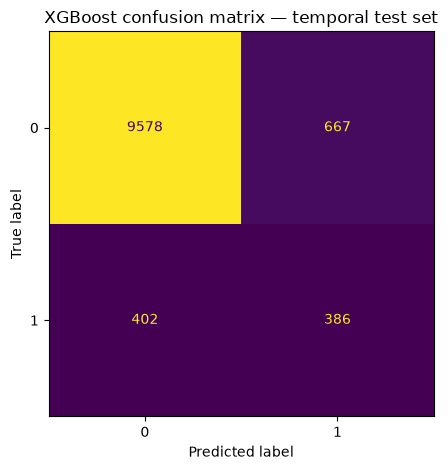

In [9]:

main_eval = evaluate_binary_model(
    model,
    X_test_t,
    y_test,
)

print(f"ROC-AUC: {main_eval['roc_auc']:.4f}")
print(f"PR-AUC:  {main_eval['pr_auc']:.4f}")

print("\nClassification report (threshold = 0.5):")
print(
    classification_report(
        y_test,
        main_eval["prediction"],
        digits=4,
    )
)

main_performance = pd.DataFrame([
    {
        "model": "main_with_month",
        "split": "temporal_holdout",
        "events": len(test),
        "positive_prevalence": y_test.mean(),
        "roc_auc": main_eval["roc_auc"],
        "pr_auc": main_eval["pr_auc"],
    }
])

main_performance.to_csv(
    OUTPUT_DIR / "main_temporal_test_performance.csv",
    index=False,
)

fig, ax = plt.subplots(figsize=(5.5, 4.8))
ConfusionMatrixDisplay(
    confusion_matrix=confusion_matrix(
        y_test,
        main_eval["prediction"],
    ),
    display_labels=[0, 1],
).plot(ax=ax, colorbar=False)

ax.set_title("XGBoost confusion matrix — temporal test set")
fig.tight_layout()
fig.savefig(
    FIGURE_DIR / "xgboost_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()



## 9. Interpretable Modeling Support with XGBoost SHAP

A análise principal de explicabilidade é calculada sobre o **conjunto temporal de teste**, isto é, eventos posteriores aos utilizados no ajuste do modelo.

Com `SHAP_SCOPE="test"`, `SHAP_MAX_ROWS=None` e `SHAP_APPROXIMATE=False`, todos os eventos do teste recebem explicações Tree SHAP exatas.

Isso permite interpretar o comportamento do modelo fora da amostra de treinamento.


In [10]:

if SHAP_SCOPE == "test":
    X_scope_original = X_test.copy()
    y_scope = y_test.copy()
    X_scope_t = X_test_t
    scope_name = "temporal test set"
    metadata_scope = test[["event_id", "event_time_hour_utc", TARGET]].copy()
else:
    X_scope_original = df_model[main_features].copy()
    y_scope = df_model[TARGET].astype(int).copy()
    X_scope_t = preprocessor.transform(X_scope_original)
    scope_name = "full dataset"
    metadata_scope = df_model[["event_id", "event_time_hour_utc", TARGET]].copy()

positions = choose_positions(
    len(X_scope_original),
    SHAP_MAX_ROWS,
    RANDOM_STATE,
)

X_shap_original = X_scope_original.iloc[positions].copy()
y_shap = y_scope.iloc[positions].copy()
metadata_shap = metadata_scope.iloc[positions].reset_index(drop=True)
X_shap_t = X_scope_t[positions]

if sparse.issparse(X_shap_t):
    X_shap_dense = X_shap_t.toarray()
else:
    X_shap_dense = np.asarray(X_shap_t)

print("SHAP scope:", scope_name)
print("Available events:", len(X_scope_original))
print("Events explained:", len(X_shap_original))
print("Transformed matrix:", X_shap_dense.shape)
print(
    "Positive prevalence:",
    f"{y_shap.mean()*100:.2f}%"
)


SHAP scope: temporal test set
Available events: 11033
Events explained: 11033
Transformed matrix: (11033, 104)
Positive prevalence: 7.14%


In [11]:

explainer = shap.TreeExplainer(model)

shap_values = explainer(
    X_shap_dense,
    approximate=SHAP_APPROXIMATE,
    check_additivity=not SHAP_APPROXIMATE,
)

shap_values.feature_names = transformed_feature_names

plot_feature_names = [
    compact_plot_label(name)
    for name in transformed_feature_names
]

shap_values_plot = shap.Explanation(
    values=shap_values.values,
    base_values=shap_values.base_values,
    data=shap_values.data,
    feature_names=plot_feature_names,
)

print("SHAP values:", shap_values.values.shape)


SHAP values: (11033, 104)



## 10. Global explanation of feature importance

Esta seção responde a três questões:

1. Quais atributos têm maior contribuição média absoluta para a saída do XGBoost?
2. Qual é a direção das contribuições das variáveis transformadas?
3. Quais grupos conceituais — autenticação, rede, histórico/atividade, temporal e geografia — concentram maior contribuição?

A importância global é baseada em `mean(|SHAP|)`. Ela mede magnitude de contribuição para o modelo e **não causalidade**.

Para variáveis categóricas, a importância por variável original é calculada com **grouped SHAP**: as contribuições das colunas *one-hot* são somadas por evento antes de calcular `mean(|SHAP|)`. Isso evita favorecer artificialmente variáveis com mais categorias.


In [12]:

mean_abs_shap = np.abs(
    shap_values.values
).mean(axis=0)

encoded_importance = (
    pd.DataFrame({
        "transformed_feature": transformed_feature_names,
        "mean_abs_shap": mean_abs_shap,
    })
    .sort_values("mean_abs_shap", ascending=False)
    .reset_index(drop=True)
)

source_shap = group_shap_by_source(
    transformed_feature_names,
    shap_values.values,
    numeric_features,
    categorical_features,
)

source_importance = source_importance_from_grouped_shap(
    source_shap
)

encoded_importance.to_csv(
    OUTPUT_DIR / "shap_global_encoded_features.csv",
    index=False,
)

source_importance.to_csv(
    OUTPUT_DIR / "shap_global_source_variables.csv",
    index=False,
)

display(source_importance.head(TOP_N))


,source_variable,mean_abs_shap,relative_percent
0,login_challenge_method,6.393196,42.988495
1,login_type,4.001482,26.906368
2,networks_seen_to_date,0.471920,3.173237
3,event_hour,0.436133,2.932605
4,ip_changed,0.398404,2.678906
5,prior_event_count,0.283357,1.905322
6,distinct_networks_30d,0.272596,1.832966
7,is_new_ip,0.268808,1.807494
8,month,0.266610,1.792715
9,day_of_week,0.232149,1.560995



### 10.1 Direction of global contributions

O *beeswarm* é a principal figura para a direção das contribuições. Como apoio quantitativo, são exportados dois resumos:

- direção por variável transformada;
- direção por variável original após *grouped SHAP*.


In [13]:

direction_rows = []

source_mapping = transformed_source_mapping(
    transformed_feature_names,
    numeric_features,
    categorical_features,
)

for j, feature_name in enumerate(transformed_feature_names):
    source_variable = source_mapping[j]
    shap_col = shap_values.values[:, j]
    value_col = X_shap_dense[:, j]

    row = {
        "transformed_feature": feature_name,
        "source_variable": source_variable,
        "mean_abs_shap": float(np.mean(np.abs(shap_col))),
        "mean_shap": float(np.mean(shap_col)),
        "positive_shap_share": float(np.mean(shap_col > 0)),
        "negative_shap_share": float(np.mean(shap_col < 0)),
        "n_present": np.nan,
        "mean_shap_when_present": np.nan,
        "mean_shap_when_absent": np.nan,
        "value_shap_spearman": np.nan,
    }

    if source_variable in categorical_features:
        present = value_col == 1
        absent = value_col == 0

        row["n_present"] = int(present.sum())

        if present.any():
            row["mean_shap_when_present"] = float(
                np.mean(shap_col[present])
            )

        if absent.any():
            row["mean_shap_when_absent"] = float(
                np.mean(shap_col[absent])
            )
    else:
        if np.unique(value_col).size > 1:
            rho, _ = spearmanr(value_col, shap_col)
            row["value_shap_spearman"] = float(rho)

    direction_rows.append(row)

direction_summary = (
    pd.DataFrame(direction_rows)
    .sort_values("mean_abs_shap", ascending=False)
    .reset_index(drop=True)
)

source_direction_summary = pd.DataFrame({
    "source_variable": source_shap.columns,
    "mean_abs_shap": source_shap.abs().mean(axis=0).to_numpy(),
    "mean_shap": source_shap.mean(axis=0).to_numpy(),
    "positive_shap_share": (source_shap > 0).mean(axis=0).to_numpy(),
    "negative_shap_share": (source_shap < 0).mean(axis=0).to_numpy(),
}).sort_values(
    "mean_abs_shap",
    ascending=False,
).reset_index(drop=True)

direction_summary.to_csv(
    OUTPUT_DIR / "shap_global_direction_summary.csv",
    index=False,
)

source_direction_summary.to_csv(
    OUTPUT_DIR / "shap_global_source_direction_summary.csv",
    index=False,
)

print("Original-variable direction summary:")
display(source_direction_summary.head(TOP_N))

print("\nTop transformed features with category/value-aware direction:")
display(direction_summary.head(TOP_N))


Original-variable direction summary:


C:\Users\Pena\AppData\Local\Temp\ipykernel_37648\523100194.py:44: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, _ = spearmanr(value_col, shap_col)


,source_variable,mean_abs_shap,mean_shap,positive_shap_share,negative_shap_share
0,login_challenge_method,6.393196,6.393196,1.000000,0.000000
1,login_type,4.001482,-4.001482,0.000000,1.000000
2,networks_seen_to_date,0.471920,-0.447425,0.240823,0.759177
3,event_hour,0.436133,-0.338609,0.057917,0.942083
4,ip_changed,0.398404,0.398404,1.000000,0.000000
5,prior_event_count,0.283357,-0.104046,0.620140,0.379860
6,distinct_networks_30d,0.272596,-0.253160,0.201668,0.798332
7,is_new_ip,0.268808,0.268808,1.000000,0.000000
8,month,0.266610,-0.263717,0.032448,0.967552
9,day_of_week,0.232149,-0.228247,0.057555,0.942445



Top transformed features with category/value-aware direction:


,transformed_feature,source_variable,mean_abs_shap,mean_shap,positive_shap_share,negative_shap_share,n_present,mean_shap_when_present,mean_shap_when_absent,value_shap_spearman
0,login_type_exchange,login_type,3.003978,-3.003978,0.000000,1.000000,2525.0,-2.942990,-3.022079,NaN
1,login_challenge_method_password|idv_any_phone,login_challenge_method,2.353524,2.353524,1.000000,0.000000,3.0,2.338650,2.353528,NaN
2,login_challenge_method_password|idv_preregiste...,login_challenge_method,1.311861,1.311861,1.000000,0.000000,78.0,1.231625,1.312432,NaN
3,login_type_google_password,login_type,1.153186,-1.153186,0.000000,1.000000,6016.0,-1.143945,-1.164268,NaN
4,login_challenge_method_password|knowledge_prer...,login_challenge_method,1.008532,1.008532,1.000000,0.000000,1.0,1.014994,1.008532,NaN
5,login_challenge_method_passkey,login_challenge_method,0.840616,0.840616,1.000000,0.000000,5.0,0.871478,0.840602,NaN
6,login_challenge_method_password|offline_otp,login_challenge_method,0.815505,0.815505,1.000000,0.000000,2.0,0.815883,0.815505,NaN
7,login_challenge_method_password|passkey,login_challenge_method,0.742379,-0.742379,0.000000,1.000000,15.0,-0.741991,-0.742379,NaN
8,login_challenge_method_idv_preregistered_phone...,login_challenge_method,0.592436,0.592436,1.000000,0.000000,7.0,0.592549,0.592436,NaN
9,login_challenge_method_password|device_prompt,login_challenge_method,0.512600,0.485543,0.897761,0.102239,102.0,0.386296,0.486469,NaN


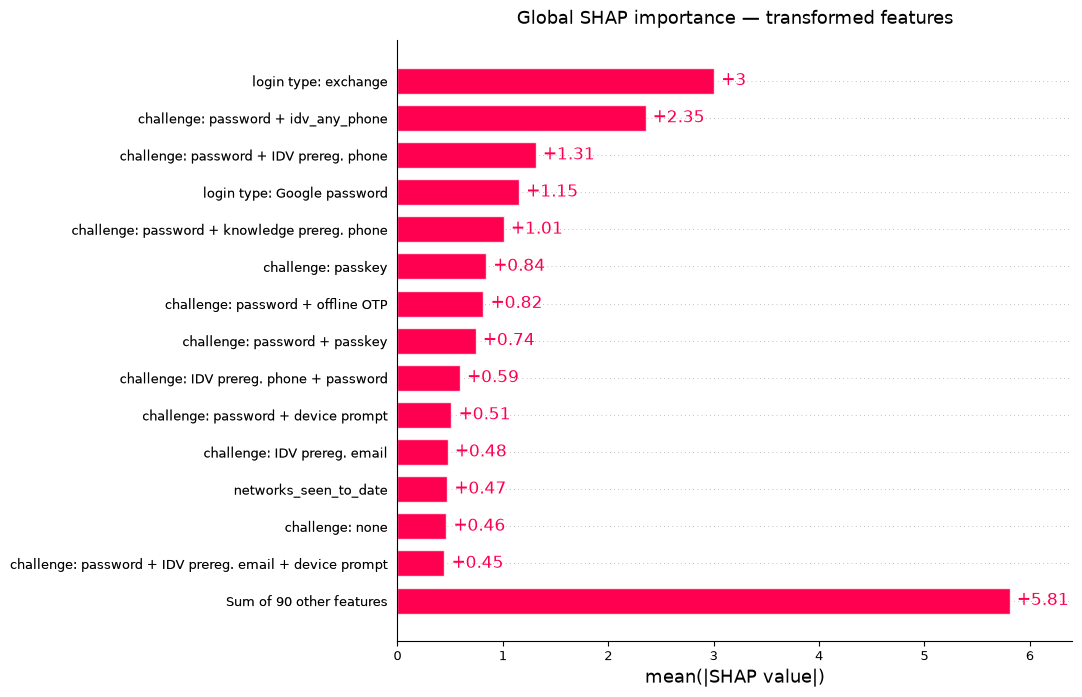

In [14]:

shap.plots.bar(
    shap_values_plot,
    max_display=TOP_N,
    show=False,
)

fig = plt.gcf()
fig.set_size_inches(12.5, 7.6)
ax = plt.gca()
ax.set_title(
    "Global SHAP importance — transformed features",
    fontsize=13,
    pad=12,
)
ax.tick_params(axis="y", labelsize=9)
ax.tick_params(axis="x", labelsize=9)

fig.subplots_adjust(
    left=0.43,
    right=0.97,
    top=0.91,
    bottom=0.12,
)

fig.savefig(
    FIGURE_DIR / "shap_global_bar_transformed.png",
    dpi=300,
    bbox_inches="tight",
)
fig.savefig(
    FIGURE_DIR / "shap_global_bar_transformed.pdf",
    bbox_inches="tight",
)
plt.show()


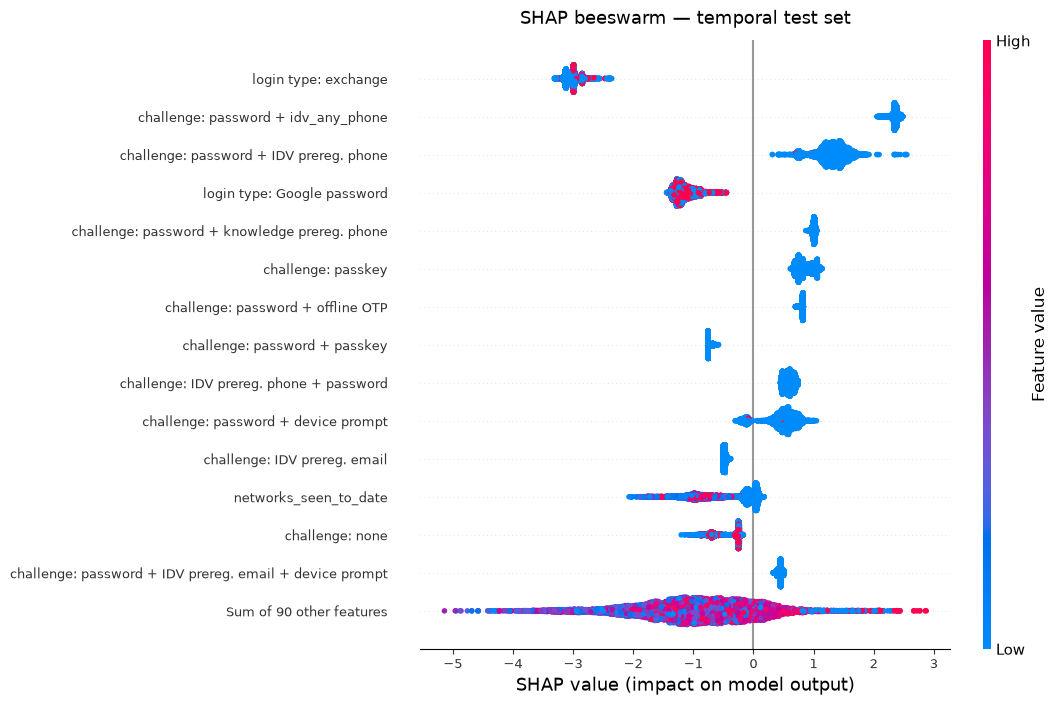

In [15]:

shap.plots.beeswarm(
    shap_values_plot,
    max_display=TOP_N,
    plot_size=(12.5, 7.8),
    show=False,
)

fig = plt.gcf()
ax = plt.gca()
ax.set_title(
    "SHAP beeswarm — temporal test set",
    fontsize=13,
    pad=12,
)
ax.tick_params(axis="y", labelsize=9)
ax.tick_params(axis="x", labelsize=9)

fig.subplots_adjust(
    left=0.40,
    right=0.93,
    top=0.91,
    bottom=0.13,
)

fig.savefig(
    FIGURE_DIR / "shap_beeswarm.png",
    dpi=300,
    bbox_inches="tight",
)
fig.savefig(
    FIGURE_DIR / "shap_beeswarm.pdf",
    bbox_inches="tight",
)
plt.show()


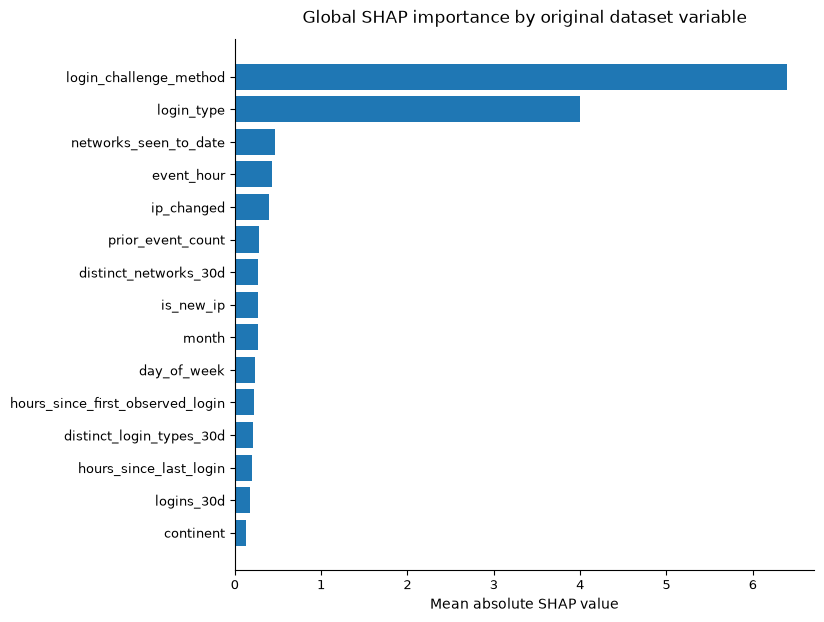

In [16]:

plot_df = (
    source_importance
    .head(TOP_N)
    .sort_values("mean_abs_shap", ascending=True)
)

fig, ax = plt.subplots(figsize=(9.2, 6.8))
ax.barh(
    plot_df["source_variable"],
    plot_df["mean_abs_shap"],
)

ax.set_xlabel("Mean absolute SHAP value")
ax.set_ylabel("")
ax.set_title(
    "Global SHAP importance by original dataset variable",
    pad=12,
)
ax.tick_params(axis="y", labelsize=9)
ax.tick_params(axis="x", labelsize=9)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.subplots_adjust(
    left=0.34,
    right=0.97,
    top=0.90,
    bottom=0.12,
)

fig.savefig(
    FIGURE_DIR / "shap_global_source_variables.png",
    dpi=300,
    bbox_inches="tight",
)
fig.savefig(
    FIGURE_DIR / "shap_global_source_variables.pdf",
    bbox_inches="tight",
)
plt.show()



### 10.2 Feature-group synthesis

As variáveis originais são agrupadas em cinco famílias conceituais:

- Authentication
- Network
- Activity/history
- Temporal
- Geography

As contribuições são novamente agrupadas por evento antes do cálculo da magnitude média de cada família conceitual.


In [17]:

assert set(
    source_importance["source_variable"]
).issubset(FEATURE_GROUPS)

group_shap = group_shap_by_concept(
    source_shap,
    FEATURE_GROUPS,
)

group_importance = (
    group_shap
    .abs()
    .mean(axis=0)
    .rename("mean_abs_shap")
    .reset_index()
    .rename(columns={"index": "group"})
    .sort_values("mean_abs_shap", ascending=False)
    .reset_index(drop=True)
)

group_importance["relative_percent"] = (
    group_importance["mean_abs_shap"]
    / group_importance["mean_abs_shap"].sum()
    * 100
)

group_importance.to_csv(
    OUTPUT_DIR / "shap_group_importance.csv",
    index=False,
)

display(group_importance)


,group,mean_abs_shap,relative_percent
0,Authentication,2.349924,49.900410
1,Temporal,0.892047,18.942535
2,Activity/history,0.744264,15.804386
3,Network,0.577352,12.260009
4,Geography,0.145640,3.092661


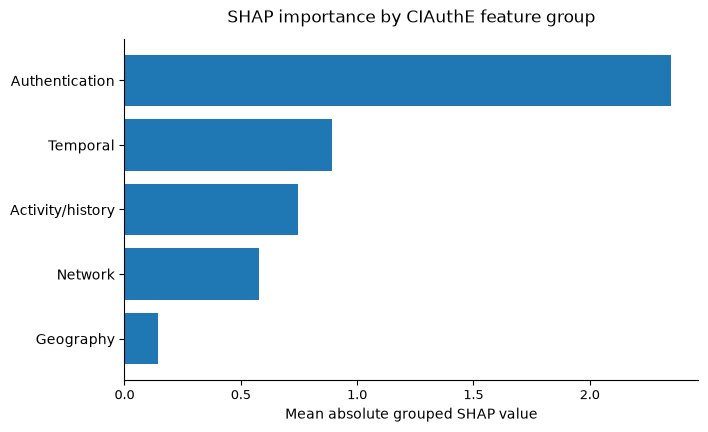

In [18]:

plot_groups = group_importance.sort_values(
    "mean_abs_shap",
    ascending=True,
)

fig, ax = plt.subplots(figsize=(8.2, 4.8))
ax.barh(
    plot_groups["group"],
    plot_groups["mean_abs_shap"],
)
ax.set_xlabel("Mean absolute grouped SHAP value")
ax.set_ylabel("")
ax.set_title(
    "SHAP importance by CIAuthE feature group",
    pad=12,
)
ax.tick_params(axis="y", labelsize=10)
ax.tick_params(axis="x", labelsize=9)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.subplots_adjust(
    left=0.27,
    right=0.97,
    top=0.88,
    bottom=0.17,
)

fig.savefig(
    FIGURE_DIR / "shap_group_importance.png",
    dpi=300,
    bbox_inches="tight",
)
fig.savefig(
    FIGURE_DIR / "shap_group_importance.pdf",
    bbox_inches="tight",
)
plt.show()


### 10.3 Dependence plots for numeric features

Top numeric variables: ['networks_seen_to_date', 'event_hour', 'ip_changed', 'prior_event_count']


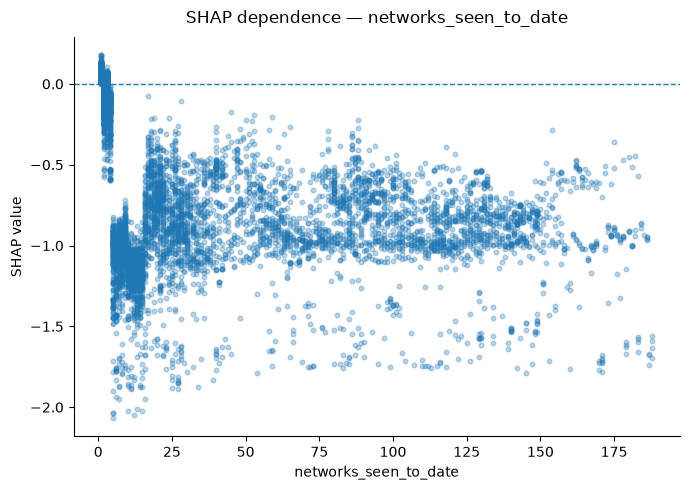

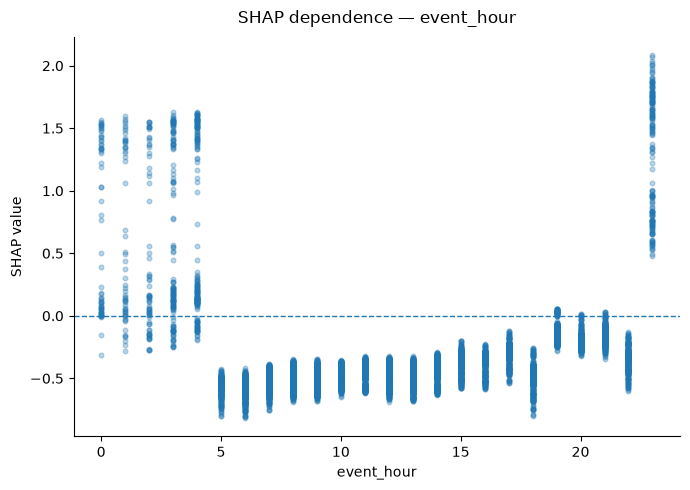

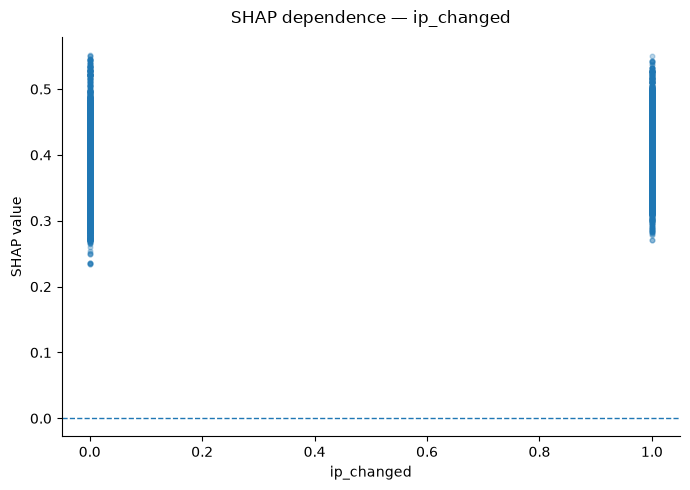

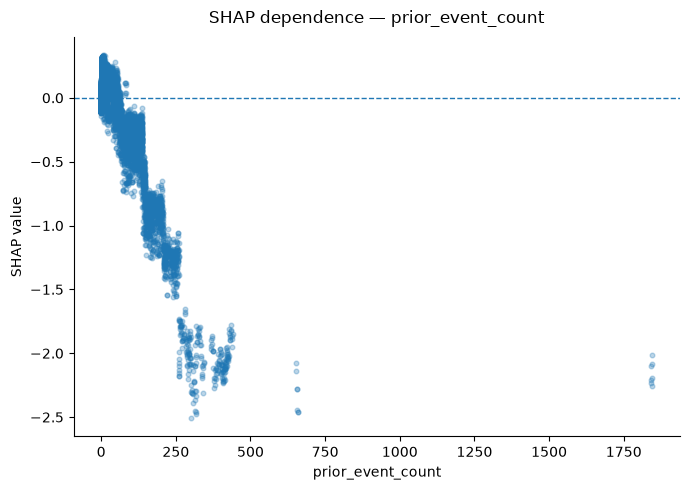

In [19]:

top_numeric_sources = (
    source_importance[
        source_importance["source_variable"].isin(
            numeric_features
        )
    ]
    .head(4)["source_variable"]
    .tolist()
)

names_array = np.asarray(transformed_feature_names)

print("Top numeric variables:", top_numeric_sources)

for source_feature in top_numeric_sources:
    matches = np.where(
        names_array == source_feature
    )[0]

    if len(matches) != 1:
        print("Skipping:", source_feature)
        continue

    j = int(matches[0])

    fig, ax = plt.subplots(figsize=(7.0, 5.0))
    ax.scatter(
        X_shap_dense[:, j],
        shap_values.values[:, j],
        alpha=0.30,
        s=11,
    )
    ax.axhline(0, linewidth=1, linestyle="--")
    ax.set_xlabel(source_feature)
    ax.set_ylabel("SHAP value")
    ax.set_title(
        f"SHAP dependence — {source_feature}",
        pad=10,
    )
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    fig.tight_layout()

    fig.savefig(
        FIGURE_DIR / f"shap_dependence_{source_feature}.png",
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()



## 11. Local explanations at event level

As explicações locais mostram como as **variáveis originais** contribuem para uma saída individual do modelo.

Para evitar seleção subjetiva, o notebook utiliza uma regra determinística:

- **highest-score event**: evento do conjunto SHAP com maior score previsto para `provider_suspicious=1`;
- **lowest-score event**: evento com menor score previsto.

O `event_id`, o valor observado de cada variável e as principais contribuições positivas e negativas são exportados para permitir que o exemplo utilizado no artigo seja explicitamente identificado.

Como o modelo utiliza ponderação de classe, o valor produzido por `predict_proba` é tratado como **class-1 model score**, e não como probabilidade calibrada de comprometimento.


In [20]:

shap_class1_scores = model.predict_proba(
    X_shap_t
)[:, 1]

highest_position = int(np.argmax(shap_class1_scores))
lowest_position = int(np.argmin(shap_class1_scores))

selected_local_events = pd.DataFrame([
    {
        "selection_rule": "highest_score",
        "position": highest_position,
        "event_id": metadata_shap.loc[highest_position, "event_id"],
        "event_time_hour_utc": metadata_shap.loc[highest_position, "event_time_hour_utc"],
        "observed_provider_suspicious": int(
            metadata_shap.loc[highest_position, TARGET]
        ),
        "class1_model_score": float(
            shap_class1_scores[highest_position]
        ),
    },
    {
        "selection_rule": "lowest_score",
        "position": lowest_position,
        "event_id": metadata_shap.loc[lowest_position, "event_id"],
        "event_time_hour_utc": metadata_shap.loc[lowest_position, "event_time_hour_utc"],
        "observed_provider_suspicious": int(
            metadata_shap.loc[lowest_position, TARGET]
        ),
        "class1_model_score": float(
            shap_class1_scores[lowest_position]
        ),
    },
])

selected_local_events.to_csv(
    OUTPUT_DIR / "local_selected_events.csv",
    index=False,
)

display(selected_local_events)


,selection_rule,position,event_id,event_time_hour_utc,observed_provider_suspicious,class1_model_score
0,highest_score,5833,E07070d1a4c6219ed3c2335ab693c9119,2026-06-30 03:00:00+00:00,1,9.946038e-01
1,lowest_score,10318,Ee3a5695316b262d8b8b7f1769355a6e7,2026-08-07 13:00:00+00:00,0,5.363924e-07


In [21]:

def local_contribution_table(position, selection_rule, max_rows=12):
    event_grouped_shap = source_shap.iloc[position]
    original_row = X_shap_original.iloc[position]

    rows = []

    for source_variable, shap_value in event_grouped_shap.items():
        rows.append({
            "source_variable": source_variable,
            "observed_value": original_row[source_variable],
            "shap_value": shap_value,
            "abs_shap": abs(shap_value),
            "direction": (
                "toward provider_suspicious=1"
                if shap_value > 0
                else (
                    "toward provider_suspicious=0"
                    if shap_value < 0
                    else "neutral"
                )
            ),
        })

    table = (
        pd.DataFrame(rows)
        .sort_values("abs_shap", ascending=False)
        .head(max_rows)
        .reset_index(drop=True)
    )

    event_row = selected_local_events.loc[
        selected_local_events["selection_rule"].eq(selection_rule)
    ].iloc[0]

    table.insert(0, "selection_rule", selection_rule)
    table.insert(1, "event_id", event_row["event_id"])
    table.insert(2, "class1_model_score", event_row["class1_model_score"])
    table.insert(
        3,
        "observed_provider_suspicious",
        event_row["observed_provider_suspicious"],
    )

    return table


local_highest = local_contribution_table(
    highest_position,
    "highest_score",
)

local_lowest = local_contribution_table(
    lowest_position,
    "lowest_score",
)

local_highest.to_csv(
    OUTPUT_DIR / "local_explanation_highest_score.csv",
    index=False,
)

local_lowest.to_csv(
    OUTPUT_DIR / "local_explanation_lowest_score.csv",
    index=False,
)

print("Highest-score event explanation — grouped by original variable:")
display(local_highest)

print("\nLowest-score event explanation — grouped by original variable:")
display(local_lowest)


Highest-score event explanation — grouped by original variable:


,selection_rule,event_id,class1_model_score,observed_provider_suspicious,source_variable,observed_value,shap_value,abs_shap,direction
0,highest_score,E07070d1a4c6219ed3c2335ab693c9119,0.994604,1,login_challenge_method,none,4.897010,4.897010,toward provider_suspicious=1
1,highest_score,E07070d1a4c6219ed3c2335ab693c9119,0.994604,1,login_type,google_password,-4.026123,4.026123,toward provider_suspicious=0
2,highest_score,E07070d1a4c6219ed3c2335ab693c9119,0.994604,1,event_hour,3,1.578531,1.578531,toward provider_suspicious=1
3,highest_score,E07070d1a4c6219ed3c2335ab693c9119,0.994604,1,hours_since_last_login,1435.7547,-0.776190,0.776190,toward provider_suspicious=0
4,highest_score,E07070d1a4c6219ed3c2335ab693c9119,0.994604,1,ip_changed,1,0.358215,0.358215,toward provider_suspicious=1
5,highest_score,E07070d1a4c6219ed3c2335ab693c9119,0.994604,1,continent,South America,-0.300995,0.300995,toward provider_suspicious=0
6,highest_score,E07070d1a4c6219ed3c2335ab693c9119,0.994604,1,day_of_week,1,-0.291371,0.291371,toward provider_suspicious=0
7,highest_score,E07070d1a4c6219ed3c2335ab693c9119,0.994604,1,hours_since_first_observed_login,4053.1228,-0.250858,0.250858,toward provider_suspicious=0
8,highest_score,E07070d1a4c6219ed3c2335ab693c9119,0.994604,1,distinct_networks_30d,1,-0.240549,0.240549,toward provider_suspicious=0
9,highest_score,E07070d1a4c6219ed3c2335ab693c9119,0.994604,1,logins_30d,1,-0.205932,0.205932,toward provider_suspicious=0



Lowest-score event explanation — grouped by original variable:


,selection_rule,event_id,class1_model_score,observed_provider_suspicious,source_variable,observed_value,shap_value,abs_shap,direction
0,lowest_score,Ee3a5695316b262d8b8b7f1769355a6e7,5.363924e-07,0,login_challenge_method,none,8.131537,8.131537,toward provider_suspicious=1
1,lowest_score,Ee3a5695316b262d8b8b7f1769355a6e7,5.363924e-07,0,login_type,exchange,-4.011708,4.011708,toward provider_suspicious=0
2,lowest_score,Ee3a5695316b262d8b8b7f1769355a6e7,5.363924e-07,0,prior_event_count,247,-1.195559,1.195559,toward provider_suspicious=0
3,lowest_score,Ee3a5695316b262d8b8b7f1769355a6e7,5.363924e-07,0,logins_30d,78,-1.054386,1.054386,toward provider_suspicious=0
4,lowest_score,Ee3a5695316b262d8b8b7f1769355a6e7,5.363924e-07,0,networks_seen_to_date,184,-0.865280,0.865280,toward provider_suspicious=0
5,lowest_score,Ee3a5695316b262d8b8b7f1769355a6e7,5.363924e-07,0,hours_since_first_observed_login,5514.2994,-0.576584,0.576584,toward provider_suspicious=0
6,lowest_score,Ee3a5695316b262d8b8b7f1769355a6e7,5.363924e-07,0,event_hour,13,-0.502601,0.502601,toward provider_suspicious=0
7,lowest_score,Ee3a5695316b262d8b8b7f1769355a6e7,5.363924e-07,0,active_days_30d,24,-0.493826,0.493826,toward provider_suspicious=0
8,lowest_score,Ee3a5695316b262d8b8b7f1769355a6e7,5.363924e-07,0,distinct_networks_30d,24,-0.465387,0.465387,toward provider_suspicious=0
9,lowest_score,Ee3a5695316b262d8b8b7f1769355a6e7,5.363924e-07,0,ip_changed,0,0.317860,0.317860,toward provider_suspicious=1


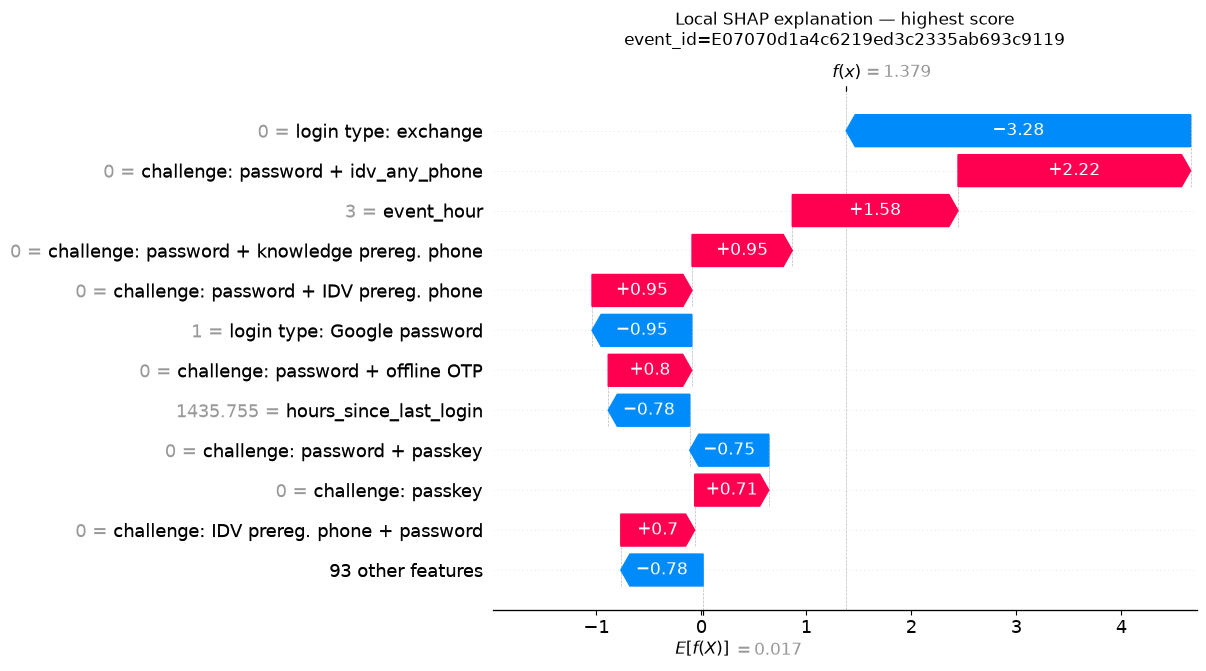

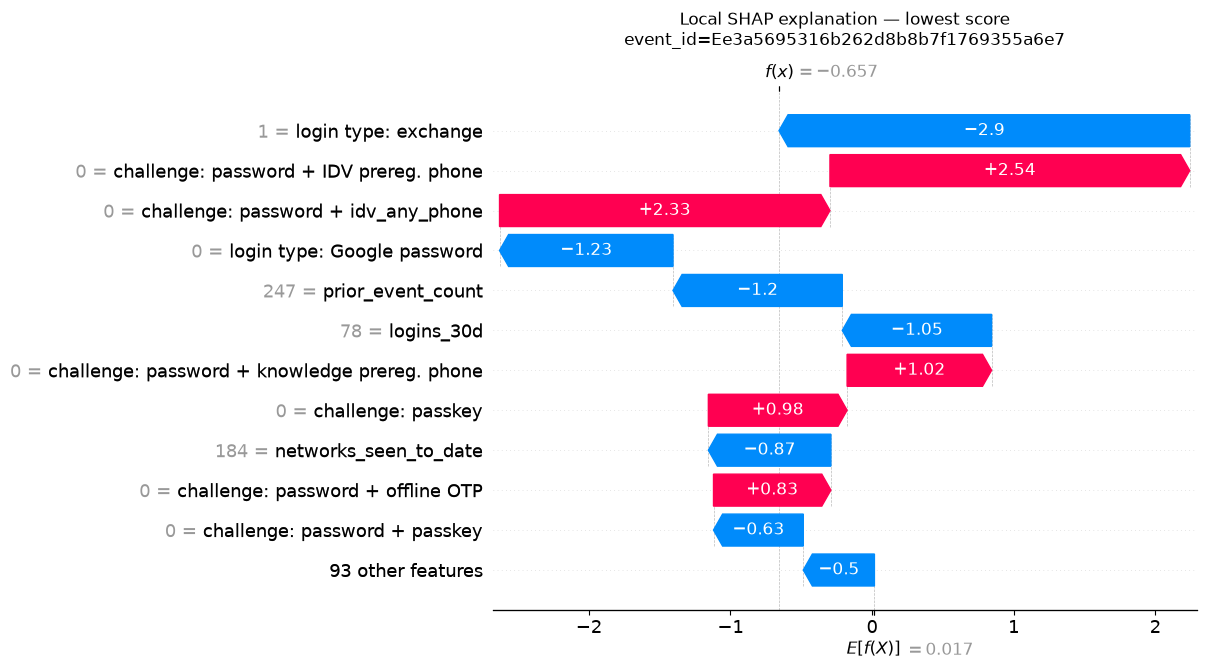

In [23]:

for position, label in [
    (highest_position, "highest_score"),
    (lowest_position, "lowest_score"),
]:
    shap.plots.waterfall(
        shap_values_plot[position],
        max_display=12,
        show=False,
    )

    event_row = selected_local_events.loc[
        selected_local_events["selection_rule"].eq(label)
    ].iloc[0]

    fig = plt.gcf()
    fig.set_size_inches(12.8, 7.2)
    ax = plt.gca()
    ax.set_title(
        (
            f"Local SHAP explanation — {label.replace('_', ' ')}\n"
            f"event_id={event_row['event_id']}"
        ),
        fontsize=12,
        pad=14,
    )
    ax.tick_params(axis="y", labelsize=9)

    fig.subplots_adjust(
        left=0.42,
        right=0.97,
        top=0.84,
        bottom=0.12,
    )

    fig.savefig(
        FIGURE_DIR / f"shap_waterfall_{label}.png",
        dpi=300,
        bbox_inches="tight",
    )
    fig.savefig(
        FIGURE_DIR / f"shap_waterfall_{label}.pdf",
        bbox_inches="tight",
    )
    plt.show()


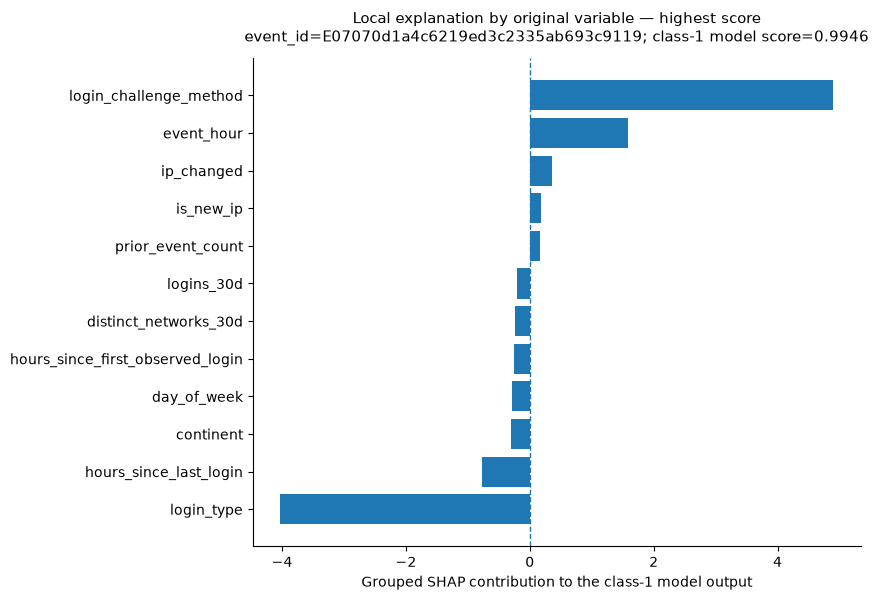

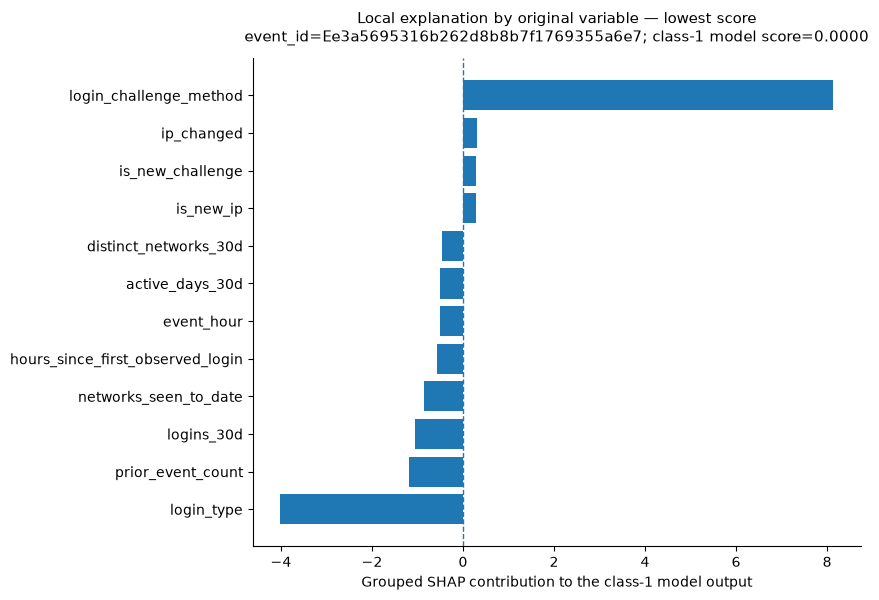

In [24]:

# Article-ready local explanation at ORIGINAL-variable level.
for table, label in [
    (local_highest, "highest_score"),
    (local_lowest, "lowest_score"),
]:
    plot_local = (
        table
        .sort_values("shap_value", ascending=True)
        .copy()
    )

    fig, ax = plt.subplots(figsize=(9.5, 6.6))

    ax.barh(
        plot_local["source_variable"],
        plot_local["shap_value"],
    )

    ax.axvline(
        0,
        linewidth=1,
        linestyle="--",
    )

    ax.set_xlabel(
        "Grouped SHAP contribution to the class-1 model output"
    )
    ax.set_ylabel("")

    event_id = plot_local["event_id"].iloc[0]
    score = plot_local["class1_model_score"].iloc[0]

    ax.set_title(
        (
            f"Local explanation by original variable — {label.replace('_', ' ')}\n"
            f"event_id={event_id}; class-1 model score={score:.4f}"
        ),
        fontsize=11,
        pad=12,
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    fig.subplots_adjust(
        left=0.33,
        right=0.97,
        top=0.86,
        bottom=0.12,
    )

    fig.savefig(
        FIGURE_DIR / f"local_grouped_contribution_{label}.png",
        dpi=300,
        bbox_inches="tight",
    )

    fig.savefig(
        FIGURE_DIR / f"local_grouped_contribution_{label}.pdf",
        bbox_inches="tight",
    )

    plt.show()



## 12. Temporal stability of explanations — rolling temporal validation

A *rolling temporal validation* utiliza janela expansiva:

- meses anteriores formam o treino;
- o mês seguinte é reservado para teste;
- preprocessing e modelo são reajustados apenas com dados anteriores;
- os hiperparâmetros permanecem fixos;
- a importância SHAP é recalculada para o teste de cada fold.

A estabilidade dos rankings de importância é posteriormente quantificada pela correlação de Spearman.


In [25]:

rolling_df = df_model.copy()
rolling_df["year_month"] = (
    rolling_df["event_time_hour_utc"]
    .dt.strftime("%Y-%m")
)

observed_months = sorted(
    rolling_df["year_month"].unique().tolist()
)

candidate_test_months = observed_months[
    ROLLING_INITIAL_TRAIN_MONTHS:
]

if (
    ROLLING_EXCLUDE_PARTIAL_LAST_MONTH
    and candidate_test_months
):
    candidate_test_months = candidate_test_months[:-1]

print("Observed months:", observed_months)
print("Rolling test months:", candidate_test_months)

assert len(candidate_test_months) >= 2


Observed months: ['2025-12', '2026-01', '2026-02', '2026-03', '2026-04', '2026-05', '2026-06', '2026-07', '2026-08']
Rolling test months: ['2026-04', '2026-05', '2026-06', '2026-07']


In [26]:

rolling_metrics = []
rolling_source_tables = {}

for fold_index, test_month in enumerate(
    candidate_test_months,
    start=1,
):
    test_month_index = observed_months.index(
        test_month
    )

    training_months = observed_months[
        :test_month_index
    ]

    fold_train = rolling_df[
        rolling_df["year_month"].isin(
            training_months
        )
    ].copy()

    fold_test = rolling_df[
        rolling_df["year_month"].eq(
            test_month
        )
    ].copy()

    if (
        fold_train[TARGET].nunique() < 2
        or fold_test[TARGET].nunique() < 2
    ):
        print(
            "Skipping fold due to single-class data:",
            test_month,
        )
        continue

    fold_preprocessor, fold_numeric, fold_categorical = (
        build_preprocessor(BASE_FEATURES)
    )

    X_fold_train = fold_train[BASE_FEATURES]
    y_fold_train = fold_train[TARGET].astype(int)

    X_fold_test = fold_test[BASE_FEATURES]
    y_fold_test = fold_test[TARGET].astype(int)

    X_fold_train_t = (
        fold_preprocessor.fit_transform(
            X_fold_train
        )
    )
    X_fold_test_t = (
        fold_preprocessor.transform(
            X_fold_test
        )
    )

    fold_feature_names = clean_transformed_names(
        fold_preprocessor
        .get_feature_names_out()
        .tolist()
    )

    fold_model, fold_weight = make_model(
        y_fold_train
    )

    fold_model.fit(
        X_fold_train_t,
        y_fold_train,
        verbose=False,
    )

    fold_eval = evaluate_binary_model(
        fold_model,
        X_fold_test_t,
        y_fold_test,
    )

    positions = choose_positions(
        len(fold_test),
        ROLLING_SHAP_MAX_ROWS,
        RANDOM_STATE + fold_index,
    )

    X_fold_shap_t = X_fold_test_t[
        positions
    ]

    fold_contrib = exact_xgboost_contributions(
        fold_model,
        X_fold_shap_t,
    )

    fold_source_shap = group_shap_by_source(
        fold_feature_names,
        fold_contrib,
        fold_numeric,
        fold_categorical,
    )

    fold_source = source_importance_from_grouped_shap(
        fold_source_shap
    )

    fold_source["test_month"] = test_month
    rolling_source_tables[test_month] = (
        fold_source.copy()
    )

    rolling_metrics.append({
        "fold": fold_index,
        "train_start": training_months[0],
        "train_end": training_months[-1],
        "test_month": test_month,
        "train_events": len(fold_train),
        "test_events": len(fold_test),
        "test_positive_prevalence": y_fold_test.mean(),
        "roc_auc": fold_eval["roc_auc"],
        "pr_auc": fold_eval["pr_auc"],
        "shap_events": len(positions),
        "scale_pos_weight": fold_weight,
    })

rolling_metrics = pd.DataFrame(
    rolling_metrics
)

assert len(rolling_metrics) >= 2

display(rolling_metrics)

rolling_metrics.to_csv(
    OUTPUT_DIR / "rolling_temporal_metrics.csv",
    index=False,
)


,fold,train_start,train_end,test_month,train_events,test_events,test_positive_prevalence,roc_auc,pr_auc,shap_events,scale_pos_weight
0,1,2025-12,2026-03,2026-04,30704,10516,0.104032,0.891232,0.510792,10516,9.238079
1,2,2025-12,2026-04,2026-05,41220,9733,0.104593,0.917922,0.524090,9733,9.070853
2,3,2025-12,2026-05,2026-06,50953,17961,0.112522,0.738079,0.340110,17961,8.969282
3,4,2025-12,2026-06,2026-07,68914,3172,0.013241,0.978062,0.389912,3172,8.662647


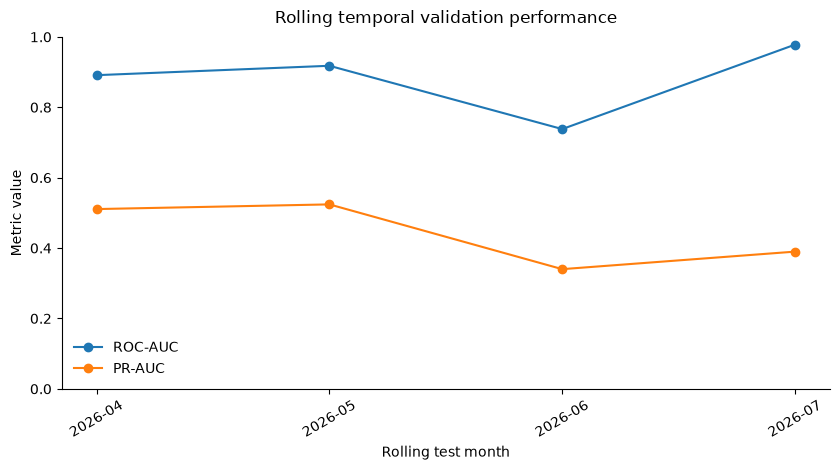

In [27]:

fig, ax = plt.subplots(figsize=(8.5, 4.8))

ax.plot(
    rolling_metrics["test_month"],
    rolling_metrics["roc_auc"],
    marker="o",
    label="ROC-AUC",
)
ax.plot(
    rolling_metrics["test_month"],
    rolling_metrics["pr_auc"],
    marker="o",
    label="PR-AUC",
)

ax.set_xlabel("Rolling test month")
ax.set_ylabel("Metric value")
ax.set_title(
    "Rolling temporal validation performance",
    pad=10,
)
ax.set_ylim(0, 1)
ax.tick_params(axis="x", rotation=30)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(frameon=False)

fig.tight_layout()

fig.savefig(
    FIGURE_DIR / "rolling_temporal_performance.png",
    dpi=300,
    bbox_inches="tight",
)
fig.savefig(
    FIGURE_DIR / "rolling_temporal_performance.pdf",
    bbox_inches="tight",
)
plt.show()



## 13. Stability of global SHAP rankings

Esta seção compara os rankings de importância SHAP entre os folds temporais.

Uma correlação de Spearman elevada indica que a hierarquia das variáveis utilizadas pelo modelo permanece relativamente estável ao longo dos diferentes períodos avaliados. Isso não prova ausência de *drift*, mas fornece evidência sobre estabilidade da explicação global.


In [28]:

all_sources = sorted(
    set().union(
        *[
            set(t["source_variable"])
            for t in rolling_source_tables.values()
        ]
    )
)

rolling_importance_matrix = pd.DataFrame(
    index=all_sources
)

for test_month, table in (
    rolling_source_tables.items()
):
    series = table.set_index(
        "source_variable"
    )["mean_abs_shap"]

    rolling_importance_matrix[
        test_month
    ] = series.reindex(
        all_sources
    ).fillna(0.0)

rolling_importance_matrix.index.name = (
    "source_variable"
)

rolling_importance_matrix.to_csv(
    OUTPUT_DIR
    / "rolling_shap_source_importance.csv"
)

rank_matrix = (
    rolling_importance_matrix
    .rank(
        axis=0,
        ascending=False,
        method="average",
    )
)

months = rolling_importance_matrix.columns.tolist()

stability = pd.DataFrame(
    np.eye(len(months)),
    index=months,
    columns=months,
    dtype=float,
)

for i, a in enumerate(months):
    for j, b in enumerate(months):
        if i >= j:
            continue

        rho, _ = spearmanr(
            rank_matrix[a],
            rank_matrix[b],
        )

        stability.loc[a, b] = rho
        stability.loc[b, a] = rho

display(stability)

stability.to_csv(
    OUTPUT_DIR
    / "rolling_shap_rank_spearman.csv"
)

upper_triangle = [
    stability.iloc[i, j]
    for i in range(len(months))
    for j in range(i + 1, len(months))
]

mean_rank_stability = float(
    np.mean(upper_triangle)
)

print(
    "Mean pairwise Spearman rank stability:",
    f"{mean_rank_stability:.4f}",
)


,2026-04,2026-05,2026-06,2026-07
2026-04,1.000000,0.963231,0.931247,0.920816
2026-05,0.963231,1.000000,0.956352,0.957656
2026-06,0.931247,0.956352,1.000000,0.929587
2026-07,0.920816,0.957656,0.929587,1.000000


Mean pairwise Spearman rank stability: 0.9431


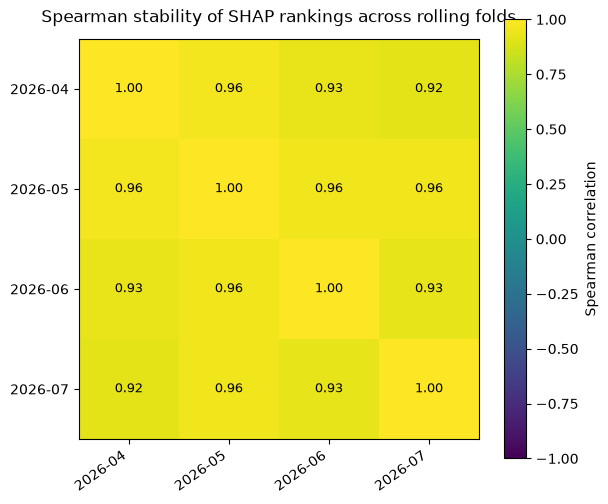

In [29]:

fig, ax = plt.subplots(
    figsize=(6.2, 5.3)
)

image = ax.imshow(
    stability.to_numpy(),
    vmin=-1,
    vmax=1,
)

ax.set_xticks(
    np.arange(len(months))
)
ax.set_yticks(
    np.arange(len(months))
)

ax.set_xticklabels(
    months,
    rotation=35,
    ha="right",
)
ax.set_yticklabels(months)

ax.set_title(
    "Spearman stability of SHAP rankings across rolling folds",
    pad=12,
)

for i in range(len(months)):
    for j in range(len(months)):
        ax.text(
            j,
            i,
            f"{stability.iloc[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=9,
        )

fig.colorbar(
    image,
    ax=ax,
    label="Spearman correlation",
)

fig.tight_layout()

fig.savefig(
    FIGURE_DIR / "rolling_shap_rank_stability.png",
    dpi=300,
    bbox_inches="tight",
)
fig.savefig(
    FIGURE_DIR / "rolling_shap_rank_stability.pdf",
    bbox_inches="tight",
)
plt.show()



## 14. Sensitivity analysis: com e sem `month`

`month` é uma variável temporal interpretável, mas também pode capturar sazonalidade ou diferenças de composição temporal.

Esta análise mantém o mesmo split temporal principal e compara:

- modelo principal com `month`;
- modelo alternativo sem `month`.

A comparação considera desempenho e estabilidade do ranking global SHAP.


In [30]:

features_without_month = [
    c for c in BASE_FEATURES
    if c != "month"
]

no_month_preprocessor, no_month_numeric, no_month_categorical = (
    build_preprocessor(
        features_without_month
    )
)

X_nm_train = train[
    features_without_month
]
X_nm_test = test[
    features_without_month
]

X_nm_train_t = (
    no_month_preprocessor.fit_transform(
        X_nm_train
    )
)
X_nm_test_t = (
    no_month_preprocessor.transform(
        X_nm_test
    )
)

no_month_names = clean_transformed_names(
    no_month_preprocessor
    .get_feature_names_out()
    .tolist()
)

no_month_model, no_month_weight = (
    make_model(y_train)
)

no_month_model.fit(
    X_nm_train_t,
    y_train,
    verbose=False,
)

no_month_eval = evaluate_binary_model(
    no_month_model,
    X_nm_test_t,
    y_test,
)

print(
    "With month:",
    f"ROC-AUC={main_eval['roc_auc']:.4f}",
    f"PR-AUC={main_eval['pr_auc']:.4f}",
)
print(
    "Without month:",
    f"ROC-AUC={no_month_eval['roc_auc']:.4f}",
    f"PR-AUC={no_month_eval['pr_auc']:.4f}",
)

month_sensitivity_performance = pd.DataFrame([
    {
        "configuration": "with_month",
        "roc_auc": main_eval["roc_auc"],
        "pr_auc": main_eval["pr_auc"],
    },
    {
        "configuration": "without_month",
        "roc_auc": no_month_eval["roc_auc"],
        "pr_auc": no_month_eval["pr_auc"],
    },
])

month_sensitivity_performance.to_csv(
    OUTPUT_DIR
    / "month_sensitivity_performance.csv",
    index=False,
)


With month: ROC-AUC=0.8996 PR-AUC=0.4087
Without month: ROC-AUC=0.8709 PR-AUC=0.3771


In [31]:

# Exact SHAP contributions on the same temporal test events.
main_exact_contrib = (
    exact_xgboost_contributions(
        model,
        X_test_t,
    )
)

no_month_exact_contrib = (
    exact_xgboost_contributions(
        no_month_model,
        X_nm_test_t,
    )
)

main_exact_source_shap = group_shap_by_source(
    transformed_feature_names,
    main_exact_contrib,
    numeric_features,
    categorical_features,
)

no_month_source_shap = group_shap_by_source(
    no_month_names,
    no_month_exact_contrib,
    no_month_numeric,
    no_month_categorical,
)

main_exact_source = source_importance_from_grouped_shap(
    main_exact_source_shap
)

no_month_source = source_importance_from_grouped_shap(
    no_month_source_shap
)

comparison = (
    main_exact_source[
        ["source_variable", "mean_abs_shap"]
    ]
    .rename(
        columns={
            "mean_abs_shap":
            "mean_abs_shap_with_month"
        }
    )
    .merge(
        no_month_source[
            ["source_variable", "mean_abs_shap"]
        ].rename(
            columns={
                "mean_abs_shap":
                "mean_abs_shap_without_month"
            }
        ),
        on="source_variable",
        how="outer",
    )
    .fillna(0.0)
)

shared = comparison[
    comparison["source_variable"] != "month"
].copy()

shared["rank_with_month"] = (
    shared["mean_abs_shap_with_month"]
    .rank(
        ascending=False,
        method="average",
    )
)

shared["rank_without_month"] = (
    shared["mean_abs_shap_without_month"]
    .rank(
        ascending=False,
        method="average",
    )
)

month_rank_rho, _ = spearmanr(
    shared["rank_with_month"],
    shared["rank_without_month"],
)

shared["rank_shift"] = (
    shared["rank_without_month"]
    - shared["rank_with_month"]
)

shared = shared.sort_values(
    "rank_with_month"
)

shared.to_csv(
    OUTPUT_DIR
    / "month_sensitivity_shap_ranking.csv",
    index=False,
)

print(
    "Spearman ranking correlation "
    "(excluding month itself):",
    f"{month_rank_rho:.4f}",
)

display(shared.head(15))


Spearman ranking correlation (excluding month itself): 0.9907


,source_variable,mean_abs_shap_with_month,mean_abs_shap_without_month,rank_with_month,rank_without_month,rank_shift
29,login_type,1.428505,1.450637,1.0,1.0,0.0
35,networks_seen_to_date,0.687631,0.790861,2.0,2.0,0.0
24,is_new_ip,0.606916,0.591167,3.0,4.0,1.0
19,ip_country,0.480045,0.605185,4.0,3.0,-1.0
11,distinct_login_types_30d,0.406025,0.409859,5.0,5.0,0.0
13,distinct_networks_30d,0.400516,0.365214,6.0,8.0,2.0
36,prior_event_count,0.368167,0.408189,7.0,6.0,-1.0
27,login_challenge_method,0.342262,0.398485,8.0,7.0,-1.0
15,event_hour,0.266822,0.231533,9.0,9.0,0.0
18,ip_changed,0.228885,0.191428,10.0,10.0,0.0


## 15. Exportação dos artefatos

In [33]:

model.save_model(
    OUTPUT_DIR
    / "xgboost_provider_suspicious.json"
)

joblib.dump(
    preprocessor,
    OUTPUT_DIR
    / "xgboost_preprocessor.joblib",
)

summary = {
    "dataset": "CIAuthE public release",
    "events": int(len(df)),
    "actors": int(
        df["actor_pseudo_id"].nunique()
    ),
    "target": TARGET,
    "predictive_features": len(BASE_FEATURES),
    "excluded_features": EXCLUDED_FEATURES,
    "primary_split": (
        "temporal holdout approximately 70/15/15 "
        "with complete UTC-hour boundaries"
    ),
    "primary_test_events": int(len(test)),
    "primary_test_roc_auc": (
        main_eval["roc_auc"]
    ),
    "primary_test_pr_auc": (
        main_eval["pr_auc"]
    ),
    "main_shap_scope": SHAP_SCOPE,
    "main_shap_events": int(
        len(X_shap_original)
    ),
    "main_shap_approximate": (
        SHAP_APPROXIMATE
    ),
    "local_highest_score_event": selected_local_events.loc[
        selected_local_events["selection_rule"].eq("highest_score")
    ].iloc[0].to_dict(),
    "rolling_test_months": (
        rolling_metrics["test_month"].tolist()
    ),
    "rolling_mean_roc_auc": float(
        rolling_metrics["roc_auc"].mean()
    ),
    "rolling_mean_pr_auc": float(
        rolling_metrics["pr_auc"].mean()
    ),
    "rolling_mean_shap_rank_spearman": (
        mean_rank_stability
    ),
    "month_sensitivity_roc_auc_without_month": (
        no_month_eval["roc_auc"]
    ),
    "month_sensitivity_pr_auc_without_month": (
        no_month_eval["pr_auc"]
    ),
    "month_sensitivity_shap_rank_spearman": float(
        month_rank_rho
    ),
}

(
    OUTPUT_DIR
    / "xgboost_shap_temporal_summary.json"
).write_text(
    json.dumps(
        summary,
        ensure_ascii=False,
        indent=2,
    ),
    encoding="utf-8",
)

print("Outputs:", OUTPUT_DIR)


TypeError: Object of type Timestamp is not JSON serializable


## 16. Article interpretation guide

### Interpretable Modeling Support with XGBoost SHAP

O XGBoost é utilizado como modelo supervisionado de apoio para avaliar se os atributos do CIAuthE contêm estrutura informativa em relação ao sinal `provider_suspicious`.

A análise não estabelece que eventos sinalizados sejam ataques confirmados. O alvo representa apenas a indicação operacional disponível na fonte.

### Global explanation of feature importance

Para o artigo, recomenda-se utilizar em conjunto:

1. `shap_global_source_variables.pdf` — magnitude agregada por variável original;
2. `shap_beeswarm.pdf` — magnitude e direção das contribuições das variáveis transformadas;
3. `shap_group_importance.pdf` — síntese por grupo conceitual;
4. `shap_global_source_direction_summary.csv` — apoio quantitativo para direção no nível da variável original.

`provider_suspicious` **não aparece** na importância SHAP porque é a variável-alvo.

### Local explanations at event level

O arquivo `local_selected_events.csv` identifica deterministicamente os eventos escolhidos.

O arquivo `local_explanation_highest_score.csv` contém as maiores contribuições **agregadas às variáveis originais** para o evento com maior score para a classe 1 no conjunto temporal de teste. A figura `local_grouped_contribution_highest_score.pdf` é a opção recomendada para o artigo, porque evita interpretar diretamente dummies one-hot ausentes.

A expressão recomendada é **class-1 model score** ou **model output**, e não “probabilidade de ataque”.

### Temporal stability

A *rolling temporal validation* complementa a explicação pontual ao avaliar se o ranking de variáveis permanece estável ao longo de diferentes períodos. A estabilidade é quantificada pela correlação de Spearman entre rankings SHAP.

### Cuidados interpretativos

- SHAP explica o modelo, não causalidade.
- `mean(|SHAP|)` mede magnitude média da contribuição.
- sinal SHAP positivo desloca a saída para `provider_suspicious=1`;
- sinal SHAP negativo desloca a saída para `provider_suspicious=0`;
- variáveis correlacionadas podem compartilhar atribuição;
- `provider_suspicious=0` não significa evento comprovadamente legítimo.
